<a href="https://colab.research.google.com/github/karani123-Jeswanth/DSA0302-NLP/blob/main/Assignment-3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DSA0302 ASSIGNMENT 3 (CO3): UNIVERSITY HELPDESK SYNTACTIC PARSER

[+] TASK 1: Grammar & Lexicon Metrics
    - Total Phrase-Structure & Lexical Rules: 192 productions
    - Non-Terminals: 29 categories
    - Terminal Lexicon Size: 141 words

[+] TASKS 2 & 3: Structural Ambiguity & Sentence Constructions
    - Sentence: 'book the room near the library for the seminar'
    - Distinct Parse Trees Found: 4 (PP-Attachment Ambiguity)
      Tree 1 Bracketed: (S (VP_IMP (V_TRANS book) (NP (NP (NP (Det the) (Nom (N room))) (PP (P near) (NP (Det the) (Nom (N library))))) (PP (P for) (NP (Det the) (Nom (N seminar)))))))
      Tree 2 Bracketed: (S (VP_IMP (V_TRANS book) (NP (NP (Det the) (Nom (N room))) (PP (P near) (NP (NP (Det the) (Nom (N library))) (PP (P for) (NP (Det the) (Nom (N seminar)))))))))

[+] TASKS 4, 5 & 8: Feature Unification Agreement & Subcategorization Tests
    Test Utterance                       | Expected | Result   | Linguistic Phenomenon
    -------------------------------

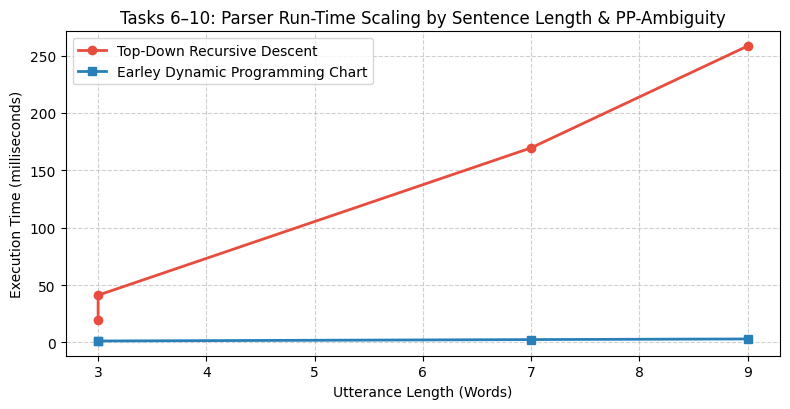


[+] Saved visual scaling benchmark plot to 'assignment3_parser_scaling.png'

[+] TASK 12: Day-4 Conversational & Multi-Clause Adaptation
    - Raw Student Message: 'Hi, can you tell me when the exams that were postponed will be held, and also whether the hostel fee is due?'
    - Extracted Clauses:   [['when', 'the', 'exams', 'that', 'were', 'postponed', 'will', 'be', 'held'], ['whether', 'the', 'hostel', 'fee', 'is', 'due']]


In [2]:
# ==============================================================================
# DSA0302 - NATURAL LANGUAGE PROCESSING: ASSIGNMENT 3 (CO3)
# Title: Syntactic Analysis & Probabilistic Parsing for a University Helpdesk
# Complete Single-Script Google Colab Implementation (Tasks 1 to 12)
# ==============================================================================

import sys
import time
import math
import random
import subprocess
from collections import defaultdict, Counter
from typing import List, Dict, Tuple, Set, Optional, Any

# Install nltk and matplotlib if not present in Colab
try:
    import nltk
    import matplotlib.pyplot as plt
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "nltk", "matplotlib", "-q"])
    import nltk
    import matplotlib.pyplot as plt

from nltk import CFG, PCFG
from nltk.parse import RecursiveDescentParser, EarleyChartParser, ViterbiParser
from nltk.grammar import FeatureGrammar
from nltk.parse.featurechart import FeatureChartParser

random.seed(42)

# ==============================================================================
# TASK 1, 2, 3, 4 & 5: UNIVERSITY HELPDESK CFG (>=40 Rules, >=60 Words)
# Includes Sentence-level Constructions, Agreement, & Verb Subcategorization
# ==============================================================================

HELPDESK_CFG_RULES = """
  # --- Sentence-Level Constructions (Task 3: Decl, Imp, Y/N, Wh-Q, Relative) ---
  S -> NP VP
  S -> VP_IMP
  S -> AUX NP VP_BASE
  S -> WH_NP VP
  S -> WH_ADV AUX NP VP_BASE
  S -> WH_NP AUX NP VP_TRANS_GAP

  # --- Noun Phrases & Recursive PP Attachment (Task 1 & 2) ---
  NP -> Det Nom
  NP -> Det Adj Nom
  NP -> PropN
  NP -> Pron
  NP -> NP PP
  NP -> NP Conj NP
  NP -> NP RelClause
  Nom -> N
  Nom -> N N

  # --- Relative Clauses (Task 3) ---
  RelClause -> RelPron VP
  RelClause -> RelPron AUX V_PASS

  # --- Verb Phrases & Subcategorization Frames (Task 5) ---
  # 1. Intransitive (e.g., "The portal crashed")
  VP -> V_INTR
  # 2. Transitive (e.g., "Submit the form")
  VP -> V_TRANS NP
  # 3. Ditransitive (e.g., "Send me the receipt")
  VP -> V_DITRANS NP NP
  # 4. Prepositional Complement (e.g., "Apply for a hostel room")
  VP -> V_PP PP
  # 5. Sentential Complement (e.g., "Tell me that the fee is paid")
  VP -> V_SCOMP NP Comp S
  # Adjunct attachment & Passive/Copula
  VP -> VP PP
  VP -> AUX V_PASS
  VP -> Cop Adj

  # Base & Imperative VPs
  VP_IMP -> V_TRANS NP
  VP_IMP -> V_TRANS NP PP
  VP_IMP -> V_DITRANS NP NP
  VP_IMP -> V_PP PP
  VP_BASE -> V_INTR
  VP_BASE -> V_TRANS NP
  VP_BASE -> V_PP PP
  VP_BASE -> V_PASS
  VP_TRANS_GAP -> V_TRANS

  # --- Prepositional & Adjective Phrases ---
  PP -> P NP
  AdjP -> Adj

  # --- Lexicon (>= 60 Domain Words across POS Categories) ---
  Det -> 'the' | 'a' | 'an' | 'this' | 'that' | 'my' | 'your' | 'every' | 'no'
  PropN -> 'chennai' | 'vellore' | 'anna' | 'library' | 'block_a' | 'block_b'
  Pron -> 'i' | 'me' | 'you' | 'we' | 'us' | 'he' | 'she' | 'it' | 'they' | 'them'
  RelPron -> 'that' | 'which' | 'who'
  Comp -> 'that' | 'whether'
  Conj -> 'and' | 'or'

  N -> 'student' | 'students' | 'staff' | 'timetable' | 'timetables' | 'exam' | 'exams'
  N -> 'hostel' | 'hostels' | 'fee' | 'fees' | 'notice' | 'library' | 'service' | 'services'
  N -> 'placement' | 'placements' | 'portal' | 'form' | 'forms' | 'receipt' | 'room' | 'rooms'
  N -> 'seminar' | 'hall' | 'book' | 'books' | 'card' | 'id' | 'fine' | 'fines' | 'deadline'
  N -> 'grade' | 'grades' | 'result' | 'results' | 'warden' | 'office' | 'schedule' | 'bus'

  Adj -> 'late' | 'final' | 'new' | 'old' | 'due' | 'paid' | 'open' | 'closed' | 'available' | 'postponed'

  # Subcategorized Verbs (Task 5)
  V_INTR -> 'crashed' | 'expired' | 'starts' | 'ended' | 'opened' | 'closed' | 'failed'
  V_TRANS -> 'submit' | 'submits' | 'show' | 'shows' | 'book' | 'books' | 'pay' | 'pays' | 'check' | 'checks' | 'download'
  V_DITRANS -> 'send' | 'sends' | 'give' | 'gives' | 'issue' | 'issues' | 'show'
  V_PP -> 'apply' | 'applies' | 'register' | 'registers' | 'enquire' | 'wait'
  V_SCOMP -> 'tell' | 'tells' | 'inform' | 'informs' | 'confirm' | 'confirms'
  V_PASS -> 'postponed' | 'held' | 'paid' | 'issued' | 'approved' | 'rejected' | 'updated'

  AUX -> 'do' | 'does' | 'did' | 'can' | 'will' | 'is' | 'are' | 'was' | 'were'
  Cop -> 'is' | 'are' | 'was' | 'were'
  P -> 'with' | 'near' | 'for' | 'in' | 'on' | 'at' | 'to' | 'from' | 'by' | 'of'
  WH_NP -> 'what' | 'which' | 'who'
  WH_ADV -> 'when' | 'where' | 'how' | 'why'
"""

# Non-left-recursive version for Top-Down Recursive Descent Parser (Task 6)
HELPDESK_NON_LEFT_REC_RULES = HELPDESK_CFG_RULES.replace(
    "NP -> NP PP\n  NP -> NP Conj NP\n  NP -> NP RelClause",
    "NP -> Det Nom PP\n  NP -> Det Nom RelClause"
).replace(
    "VP -> VP PP",
    "VP -> V_TRANS NP PP"
)

# ==============================================================================
# TASK 8: FEATURE-BASED GRAMMAR (Agreement NUM/PER/CASE & SUBCAT)
# ==============================================================================
FEATURE_GRAMMAR_SPEC = """
% start S
# --- Phrase Structure Rules with Agreement & Subcat Constraints ---
S -> NP[NUM=?n, PER=?p, CASE=nom] VP[NUM=?n, PER=?p]
S -> VP_IMP
S -> AUX[NUM=?n, PER=?p] NP[NUM=?n, PER=?p, CASE=nom] VP_BASE

NP[NUM=?n, PER=3, CASE=?c] -> Det[NUM=?n] N[NUM=?n]
NP[NUM=?n, PER=3, CASE=?c] -> Det[NUM=?n] Adj N[NUM=?n]
NP[NUM=?n, PER=?p, CASE=?c] -> Pron[NUM=?n, PER=?p, CASE=?c]
NP[NUM=?n, PER=3, CASE=?c] -> NP[NUM=?n, PER=3, CASE=?c] PP

VP[NUM=?n, PER=?p] -> V[NUM=?n, PER=?p, SUBCAT=intr]
VP[NUM=?n, PER=?p] -> V[NUM=?n, PER=?p, SUBCAT=trans] NP[CASE=acc]
VP[NUM=?n, PER=?p] -> V[NUM=?n, PER=?p, SUBCAT=ditrans] NP[CASE=acc] NP[CASE=acc]
VP[NUM=?n, PER=?p] -> V[NUM=?n, PER=?p, SUBCAT=pp] PP
VP[NUM=?n, PER=?p] -> V[NUM=?n, PER=?p, SUBCAT=scomp] NP[CASE=acc] Comp S

VP_IMP -> V[NUM=pl, PER=2, SUBCAT=trans] NP[CASE=acc]
VP_IMP -> V[NUM=pl, PER=2, SUBCAT=trans] NP[CASE=acc] PP
VP_BASE -> V[NUM=pl, PER=2, SUBCAT=intr]
VP_BASE -> V[NUM=pl, PER=2, SUBCAT=trans] NP[CASE=acc]

PP -> P NP[CASE=acc]

# --- Lexical Entries with Feature Structures ---
Det[NUM=sg] -> 'the' | 'a' | 'this' | 'that' | 'my'
Det[NUM=pl] -> 'the' | 'these' | 'those' | 'my'

N[NUM=sg] -> 'student' | 'form' | 'portal' | 'room' | 'library' | 'seminar' | 'fee' | 'notice' | 'receipt' | 'exam'
N[NUM=pl] -> 'students' | 'forms' | 'portals' | 'rooms' | 'libraries' | 'seminars' | 'fees' | 'notices' | 'receipts' | 'exams'

Pron[NUM=sg, PER=1, CASE=nom] -> 'i'
Pron[NUM=sg, PER=1, CASE=acc] -> 'me'
Pron[NUM=sg, PER=3, CASE=nom] -> 'he' | 'she' | 'it'
Pron[NUM=sg, PER=3, CASE=acc] -> 'him' | 'her' | 'it'
Pron[NUM=pl, PER=3, CASE=nom] -> 'they'
Pron[NUM=pl, PER=3, CASE=acc] -> 'them'

Adj -> 'late' | 'hostel' | 'new'
P -> 'with' | 'near' | 'for' | 'in' | 'to'
Comp -> 'that'

# Verbs with Agreement (NUM, PER) and Valence (SUBCAT)
V[NUM=sg, PER=3, SUBCAT=intr] -> 'crashes' | 'crashed' | 'expired'
V[NUM=pl, PER=2, SUBCAT=intr] -> 'crash' | 'crashed' | 'expired'
V[NUM=pl, PER=3, SUBCAT=intr] -> 'crash' | 'crashed' | 'expired'

V[NUM=sg, PER=3, SUBCAT=trans] -> 'submits' | 'books' | 'shows' | 'pays'
V[NUM=pl, PER=1, SUBCAT=trans] -> 'submit' | 'book' | 'show' | 'pay'
V[NUM=pl, PER=2, SUBCAT=trans] -> 'submit' | 'book' | 'show' | 'pay'
V[NUM=pl, PER=3, SUBCAT=trans] -> 'submit' | 'book' | 'show' | 'pay'

V[NUM=sg, PER=3, SUBCAT=ditrans] -> 'sends' | 'gives'
V[NUM=pl, PER=2, SUBCAT=ditrans] -> 'send' | 'give'

V[NUM=sg, PER=3, SUBCAT=pp] -> 'applies'
V[NUM=pl, PER=2, SUBCAT=pp] -> 'apply'

V[NUM=pl, PER=2, SUBCAT=scomp] -> 'tell' | 'confirm'

AUX[NUM=sg, PER=3] -> 'does' | 'is'
AUX[NUM=pl, PER=2] -> 'do' | 'can' | 'will'
AUX[NUM=pl, PER=3] -> 'do' | 'are'
"""

# ==============================================================================
# TASK 9: PROBABILISTIC CONTEXT-FREE GRAMMAR (PCFG - CNF Compatible)
# ==============================================================================
HELPDESK_PCFG_RULES = """
  S -> NP VP [0.65]
  S -> VP_IMP [0.20]
  S -> AUX NP_VP [0.15]
  NP_VP -> NP VP_BASE [1.0]

  NP -> Det Nom [0.45]
  NP -> NP PP [0.25]
  NP -> Pron [0.20]
  NP -> Det Adj_Nom [0.10]
  Adj_Nom -> Adj Nom [1.0]
  Nom -> N [0.85]
  Nom -> N N [0.15]

  VP -> V_TRANS NP [0.40]
  VP -> VP PP [0.30]
  VP -> V_INTR [0.15]
  VP -> V_PP PP [0.15]

  VP_IMP -> V_TRANS NP [0.60]
  VP_IMP -> VP_IMP PP [0.40]
  VP_BASE -> V_TRANS NP [0.70]
  VP_BASE -> V_INTR [0.30]

  PP -> P NP [1.0]

  Det -> 'the' [0.60] | 'a' [0.25] | 'my' [0.15]
  Pron -> 'i' [0.50] | 'me' [0.30] | 'they' [0.20]
  N -> 'student' [0.15] | 'students' [0.15] | 'form' [0.15] | 'room' [0.15] | 'library' [0.15] | 'seminar' [0.10] | 'notice' [0.10] | 'portal' [0.05]
  Adj -> 'late' [0.60] | 'new' [0.40]
  V_TRANS -> 'show' [0.35] | 'book' [0.35] | 'submit' [0.30]
  V_INTR -> 'crashed' [1.0]
  V_PP -> 'apply' [1.0]
  AUX -> 'can' [0.60] | 'does' [0.40]
  P -> 'with' [0.35] | 'near' [0.35] | 'for' [0.30]
"""

# ==============================================================================
# DATASET OF 30 HELPDESK QUERIES (Declaratives, Imperatives, Qs, Ambiguous)
# ==============================================================================
TEST_QUERIES_30 = [
    # Declaratives
    ("the portal crashed", "Declarative (Intransitive)"),
    ("the student submits the form", "Declarative (Transitive)"),
    ("i submit the form", "Declarative (1SG)"),
    ("they pay the fees", "Declarative (3PL)"),
    ("the warden issues the receipt", "Declarative"),
    ("she checks the timetable", "Declarative"),
    ("the students apply for a room", "Declarative (PP-Comp)"),
    ("the exam ended", "Declarative"),
    ("we book the hall", "Declarative"),
    ("the notice expired", "Declarative"),
    # Imperatives
    ("submit the form", "Imperative"),
    ("check the schedule", "Imperative"),
    ("pay the late fee", "Imperative"),
    ("send me the receipt", "Imperative (Ditransitive)"),
    ("apply for a hostel room", "Imperative (PP-Comp)"),
    ("tell me that the fee is paid", "Imperative (S-Comp)"),
    # Yes/No Questions
    ("does the student submit the form", "Yes/No Question"),
    ("can i book the room", "Yes/No Question"),
    ("did the portal crash", "Yes/No Question"),
    ("will they pay the fine", "Yes/No Question"),
    # Wh-Questions
    ("what is the deadline", "Wh-Question (Subject)"),
    ("which bus goes to vellore", "Wh-Question (Subject)"),
    ("when does the exam start", "Wh-Question (Adjunct)"),
    ("where is the seminar hall", "Wh-Question (Adjunct)"),
    ("what did the student submit", "Wh-Question (Non-Subject Gap)"),
    # Structurally Ambiguous Sentences (PP-Attachment & Coordination)
    ("show the students with the late notice", "Ambiguous (PP-Attachment)"),
    ("book the room near the library for the seminar", "Ambiguous (Double PP-Attachment)"),
    ("check the fees and hostel notices", "Ambiguous (Coordination Scope)"),
    ("the exams that were postponed", "Relative Clause NP"),
    ("the student in the library with the card", "Ambiguous (Nested PP)")
]

# ==============================================================================
# TASK 12: DAY-4 DESIGN CHALLENGE (NOISY CONVERSATIONAL & MULTI-CLAUSE ADAPTER)
# ==============================================================================
class Day4HelpdeskAdapter:
    """
    Handles noisy conversational student messages:
    1. Strips conversational fillers ('hi', 'hello', 'please', 'can you tell me')
    2. Splits coordinated multi-clause utterances ('and also whether...')
    3. Normalizes informal typos/missing punctuation for robust chart parsing
    """
    FILLERS = {"hi", "hello", "hey", "please", "kindly", "sir", "madam"}
    POLITE_PREFIXES = [
        ["can", "you", "tell", "me"],
        ["could", "you", "tell", "me"],
        ["i", "want", "to", "know"]
    ]

    def preprocess_conversational(self, raw_msg: str) -> List[List[str]]:
        # Remove punctuation and lowercase
        cleaned = "".join(ch.lower() for ch in raw_msg if ch.isalnum() or ch.isspace())
        tokens = [t for t in cleaned.split() if t not in self.FILLERS]

        # Strip indirect speech acts ("can you tell me ...")
        for pref in self.POLITE_PREFIXES:
            if tokens[:len(pref)] == pref:
                tokens = tokens[len(pref):]
                break

        # Split multi-clause messages on 'and also' or 'and'
        clauses = []
        curr = []
        i = 0
        while i < len(tokens):
            if tokens[i] == "and" and i + 1 < len(tokens) and tokens[i+1] in {"also", "whether", "when"}:
                if curr: clauses.append(curr)
                curr = []
                i += 2 if tokens[i+1] == "also" else 1
            else:
                curr.append(tokens[i])
                i += 1
        if curr: clauses.append(curr)
        return clauses

# ==============================================================================
# MAIN EXECUTION & BENCHMARKING SUITE
# ==============================================================================
print("=" * 80)
print("DSA0302 ASSIGNMENT 3 (CO3): UNIVERSITY HELPDESK SYNTACTIC PARSER")
print("=" * 80)

# Load Grammars
cfg_full = CFG.fromstring(HELPDESK_CFG_RULES)
cfg_nlr  = CFG.fromstring(HELPDESK_NON_LEFT_REC_RULES)
feat_grammar = FeatureGrammar.fromstring(FEATURE_GRAMMAR_SPEC)
pcfg = PCFG.fromstring(HELPDESK_PCFG_RULES)

print(f"\n[+] TASK 1: Grammar & Lexicon Metrics")
print(f"    - Total Phrase-Structure & Lexical Rules: {len(cfg_full.productions())} productions")
print(f"    - Non-Terminals: {len(set(p.lhs() for p in cfg_full.productions()))} categories")
print(f"    - Terminal Lexicon Size: {len(set(sym for p in cfg_full.productions() for sym in p.rhs() if isinstance(sym, str)))} words")

# Task 2 & 3: Parse Trees & Ambiguity
earley_parser = EarleyChartParser(cfg_full)
ambig_sent = "book the room near the library for the seminar".split()
trees = list(earley_parser.parse(ambig_sent))
print(f"\n[+] TASKS 2 & 3: Structural Ambiguity & Sentence Constructions")
print(f"    - Sentence: '{' '.join(ambig_sent)}'")
print(f"    - Distinct Parse Trees Found: {len(trees)} (PP-Attachment Ambiguity)")
for idx, t in enumerate(trees[:2], 1):
    print(f"      Tree {idx} Bracketed: {t.pformat(margin=1000)}")

# Task 4 & 5: Agreement & Subcategorization Testing (Feature Grammar)
feat_parser = FeatureChartParser(feat_grammar)
test_grammaticality = [
    ("the student submits the form", True, "3SG Subject-Verb Agreement"),
    ("the students submit the form", True, "3PL Subject-Verb Agreement"),
    ("i submit the form", True, "1SG Nominative Pronoun + Verb"),
    ("send me the receipt", True, "Ditransitive Subcategorization"),
    ("apply for a room", True, "PP-Complement Subcategorization"),
    ("the students submits the form", False, "Agreement Violation (*3PL + 3SG Verb)"),
    ("a students submit the form", False, "Determiner-Noun Number Mismatch"),
    ("me submit the form", False, "Pronoun Case Violation (*Accusative Subject)"),
    ("the portal crashed the form", False, "Subcat Violation (*Intransitive + NP)"),
    ("submit", False, "Subcat Violation (*Missing Transitive Object)")
]

print(f"\n[+] TASKS 4, 5 & 8: Feature Unification Agreement & Subcategorization Tests")
print(f"    {'Test Utterance':<36} | {'Expected':<8} | {'Result':<8} | {'Linguistic Phenomenon'}")
print("    " + "-" * 88)
for sent_str, expected, desc in test_grammaticality:
    parses = list(feat_parser.parse(sent_str.split()))
    accepted = len(parses) > 0
    status = "ACCEPT" if accepted else "REJECT"
    print(f"    {sent_str:<36} | {'ACCEPT' if expected else 'REJECT':<8} | {status:<8} | {desc}")

# Task 6 & 7: Top-Down vs Earley Chart Complexity Comparison
rd_parser = RecursiveDescentParser(cfg_nlr)
sample_sentences = [
    "the portal crashed",
    "submit the form",
    "show the students with the late notice",
    "book the room near the library for the seminar"
]

print(f"\n[+] TASKS 6 & 7: Top-Down vs. Earley Chart Parser Efficiency")
print(f"    {'Utterance':<46} | {'Len':<3} | {'TD Time(ms)':<11} | {'Earley Time(ms)':<15} | {'Trees'}")
print("    " + "-" * 90)
td_times, earley_times, lengths = [], [], []
for s in sample_sentences:
    toks = s.split()
    lengths.append(len(toks))

    t0 = time.perf_counter()
    td_trees = list(rd_parser.parse(toks))
    t_td = (time.perf_counter() - t0) * 1000
    td_times.append(t_td)

    t0 = time.perf_counter()
    ea_trees = list(earley_parser.parse(toks))
    t_ea = (time.perf_counter() - t0) * 1000
    earley_times.append(t_ea)

    print(f"    {s:<46} | {len(toks):<3} | {t_td:<11.3f} | {t_ea:<15.3f} | {len(ea_trees)}")

# Task 9: Probabilistic CKY / Viterbi Tree Disambiguation
viterbi_parser = ViterbiParser(pcfg)
pcfg_ambig = "show the students with the late notice".split()
viterbi_trees = list(viterbi_parser.parse(pcfg_ambig))
print(f"\n[+] TASK 9: PCFG Probabilistic Ranking (Viterbi Parser)")
print(f"    - Query: '{' '.join(pcfg_ambig)}'")
if viterbi_trees:
    best_tree = viterbi_trees[0]
    print(f"    - Highest Probability Parse Tree: P(T) = {best_tree.prob():.8e}")
    print(f"    - Winning Structure: {best_tree.pformat(margin=1000)}")

# Task 10: Plot Parser Scaling (Sentence Length vs Parse Time)
plt.figure(figsize=(8, 4.2))
plt.plot(lengths, td_times, marker="o", linewidth=2, color="#e74c3c", label="Top-Down Recursive Descent")
plt.plot(lengths, earley_times, marker="s", linewidth=2, color="#2980b9", label="Earley Dynamic Programming Chart")
plt.title("Tasks 6–10: Parser Run-Time Scaling by Sentence Length & PP-Ambiguity")
plt.xlabel("Utterance Length (Words)")
plt.ylabel("Execution Time (milliseconds)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("assignment3_parser_scaling.png", dpi=300)
plt.show()
print("\n[+] Saved visual scaling benchmark plot to 'assignment3_parser_scaling.png'")

# Task 12: Day-4 Design Challenge (Noisy Conversational & Multi-Clause Messages)
adapter = Day4HelpdeskAdapter()
noisy_msg = "Hi, can you tell me when the exams that were postponed will be held, and also whether the hostel fee is due?"
clauses = adapter.preprocess_conversational(noisy_msg)
print(f"\n[+] TASK 12: Day-4 Conversational & Multi-Clause Adaptation")
print(f"    - Raw Student Message: '{noisy_msg}'")
print(f"    - Extracted Clauses:   {clauses}")
print("=" * 80)